<a href="https://colab.research.google.com/github/jesseiozzio/BME-i9400-2026/blob/Lab1-_jesse/checkins/lab01_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# [Open in Colab](https://colab.research.google.com/github/dmochow/BME-i9400-2026/blob/main/labs/lab01_regression.ipynb)

# BME i9400 — Lab 1
## A Regression Baseline for Body Fat

**Fall 2026 · Released Monday, October 5 · Notebook due Tuesday, October 14, 11:59 AM EST · Defense quiz Wednesday, October 14, in class**

In this lab you carry out a complete regression study on your own: prepare a dataset, fit and
regularise a linear model, choose between models on validation data, evaluate the choice once on a
test set, and report the result. The methods are those of Meetings 6 and 7. The dataset is new.

**How the lab is assessed.** The lab component of the course is 20% of the grade, over three labs.
Within a lab, the in-class defense quiz counts 70% and the submitted notebook 30%.

- **The notebook** is graded on whether it runs from top to bottom without error, whether every task
  is complete and correct, and on the quality of the report in section 8.
- **The defense quiz** is a ten-minute written quiz at the start of Meeting 10, taken closed-book: no
laptop, no notes, no AI tools. It asks you to explain and justify what is in *your* notebook: why a step was taken, what a
  number means, what would have happened otherwise. Section 9 describes it.

**Generative AI is permitted and expected** on the notebook. Use it as you would in practice: to
write code, to debug, to check your understanding. You are responsible for every line you submit,
and the defense tests whether you can account for it without assistance. Record how you used AI in
section 9.

**Work individually.** Discussion of approach is encouraged; code and text must be your own.

---
## 1 — The question and the data

Body fat percentage is a measure of health that is difficult to measure directly. The reference
method in this dataset is underwater weighing: the subject is weighed in air and fully submerged,
body density is computed from the two weights, and body fat is estimated from density by Siri's
equation,

$$\text{body fat (\%)} = \frac{495}{\text{density}} - 450$$

Underwater weighing needs a tank, trained staff, and a cooperative subject. A tape measure and a
scale need none of these. The question of this lab is the question of Penrose, Nelson and Fisher
(*Medicine & Science in Sports & Exercise*, 1985): **how well can body fat be predicted from
circumference measurements, weight, height, and age?**

### The data

252 men, measured at the Human Performance Research Center, Brigham Young University; the data were
made public by Johnson, "Fitting Percentage of Body Fat to Simple Body Measurements", *Journal of
Statistics Education*, 1996, with permission for non-commercial use. The course copy is
`data/bodyfat.csv`, one row per man.

| Column | Meaning | Units |
|---|---|---|
| `case` | identifier, 1 to 252 | |
| `body_fat_pct` | **the target**: body fat from Siri's equation | % |
| `density` | body density from underwater weighing | g/cm³ |
| `age` | age | years |
| `weight_lb` | weight | pounds |
| `height_in` | height | inches |
| `bmi` | body mass index, computed from weight and height | kg/m² |
| `neck`, `chest`, `abdomen`, `hip`, `thigh`, `knee`, `ankle`, `biceps`, `forearm`, `wrist` | circumferences | cm |

The documentation that accompanies the data states that it is "as received" and contains "a few
errors". Finding them is part of section 2.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "figure.dpi": 110})

URL  = "https://raw.githubusercontent.com/dmochow/BME-i9400-2026/main/data/bodyfat.csv"
data = pd.read_csv(URL)

circumferences = ["neck", "chest", "abdomen", "hip", "thigh", "knee", "ankle", "biceps", "forearm", "wrist"]
measurements   = ["age", "weight_lb", "height_in", "bmi"] + circumferences      # everything a clinic can measure
target         = "body_fat_pct"

print(f"{len(data)} men, {data.shape[1]} columns")
data.describe().T[["mean", "std", "min", "max",]].round(2)

252 men, 17 columns


,mean,std,min,max
case,126.50,72.89,1.0,252.00
body_fat_pct,19.15,8.37,0.0,47.50
density,1.06,0.02,1.0,1.11
age,44.88,12.60,22.0,81.00
weight_lb,178.92,29.39,118.5,363.15
height_in,70.15,3.66,29.5,77.75
bmi,25.44,3.65,18.1,48.90
neck,37.99,2.43,31.1,51.20
chest,100.82,8.43,79.3,136.20
abdomen,92.56,10.78,69.4,148.10


---
## 2 — Data readiness

Before any model is fitted, two questions from Meeting 1: are the values plausible, and is every
column one that would be available when the model is used?

### 2.1 Implausible values

The summary table above already shows at least two impossible values. Write code that finds every
row in which **height is below 50 inches** or **body fat is at most 0%**, and look at those rows in
full. Then decide what to do with each one — correct it, remove it, or keep it — and state the
decision and the reason in the answer cell. A decision without a reason receives no credit.

> Removing a row because it is inconvenient is not a reason. A value that is physically impossible,
> or that the documentation identifies as a recording error, is. The `bmi` column, which was
> computed from weight and height before the error was made, is evidence about what the height
> should have been.

In [ ]:
# --- TODO: find the implausible rows ---
# a DataFrame: the rows with height_in < 50 or body_fat_pct <= 0
suspect = data[(data["height_in"] < 50) | (data["body_fat_pct"] <= 0)]

assert suspect is not None, "Fill in suspect."
assert len(suspect) >= 2 and ((suspect["height_in"] < 50) | (suspect["body_fat_pct"] <= 0)).all(), \
    "suspect should hold exactly the rows that meet one of the two conditions."
suspect

,case,body_fat_pct,density,age,weight_lb,height_in,bmi,neck,chest,abdomen,hip,thigh,knee,ankle,biceps,forearm,wrist
41,42,32.9,1.0250,44,205.0,29.5,29.9,36.6,106.0,104.3,115.5,70.6,42.5,23.7,33.6,28.7,17.4
181,182,0.0,1.1089,40,118.5,68.0,18.1,33.8,79.3,69.4,85.0,47.2,33.5,20.2,27.7,24.6,16.5


In [ ]:
# --- TODO: apply your decisions, producing the DataFrame `clean` ---
# For a row you correct, change the value; for a row you remove, drop it; for a row you keep, do nothing.
clean = data.copy()

# Correct Case 42 height using the BMI formula: height = sqrt(weight * 703 / BMI)
case_42_idx = clean[clean["case"] == 42].index[0]
weight_42 = clean.loc[case_42_idx, "weight_lb"]
bmi_42 = clean.loc[case_42_idx, "bmi"]
corrected_height = np.sqrt((weight_42 * 703) / bmi_42)
clean.loc[case_42_idx, "height_in"] = corrected_height

# Drop Case 182 because 0% body fat is physiologically impossible and cannot be reconstructed
clean = clean.drop(index=clean[clean["case"] == 182].index)

assert clean is not None, "Produce the DataFrame clean."
assert set(clean.columns) == set(data.columns) and len(clean) <= len(data), "clean should keep the same columns."
print(f"{len(clean)} men remain after your decisions ({len(data) - len(clean)} removed)")

251 men remain after your decisions (1 removed)


**Answer 2.1** — For each row you flagged: what is wrong, what you did, and why.

Two rows were flagged one with an inaccurate height and the other with a inaccurate BMI.

The case with a height < 50 was recaluclated using the BMI formula: height = sqrt(weight*703/BMI) and placed in a new dataset data.copy() in order to preserve the original dataset.

The case with 0% body fat couldn't be recalculated therefore it was dropped from the new dataset.



### 2.2 The column that must not be used

One column in this file is not a measurement a clinic could take with a scale and a tape measure,
and it is related to the target by a formula. Identify it, and demonstrate what happens when it is
included as a feature: fit a least squares model on all 14 measurements with and without that
column, on the full cleaned dataset, and compare the two values of $R^2$.

> Using a feature that is computed from the target, or that would only be known once the target is
> known, is called **target leakage**. The resulting model looks excellent and is useless, because
> the feature will not exist when the model is applied to a new person. Leakage of this kind is one
> of the most common ways in which a published model fails in practice (Meeting 1).

In [ ]:
from sklearn.linear_model import LinearRegression

leaky_column = "density"          # TODO: the name of the column

# --- TODO: fit on the 14 measurements plus the leaky column, and on the 14 measurements alone ---
X_with = clean[measurements + [leaky_column]].values
y = clean[target].values

model_with = LinearRegression()
model_with.fit(X_with, y)
r2_with = model_with.score(X_with, y)

X_without = clean[measurements].values
model_without = LinearRegression()
model_without.fit(X_without, y)
r2_without = model_without.score(X_without, y)

assert leaky_column is not None, "Fill in leaky_column."
assert leaky_column in clean.columns and leaky_column not in measurements + ["case", target], \
    "Name the column that is neither a clinic measurement, nor the identifier, nor the target."
assert r2_with is not None and r2_without is not None, "Fit both models."
print(f"R^2 with {leaky_column}: {r2_with:.3f}     without: {r2_without:.3f}")
assert r2_with > 0.95 > r2_without, "Including the leaky column should make the fit nearly perfect."

R^2 with density: 0.979     without: 0.745


**Answer 2.2** — Which column leaks, why (cite the formula), and why a model that used it would fail in a
clinic. The leaky column is 'density' because the target 'body_fat_pct' is directly calculated using Siri's equation, acting as a perfect mathematical proxy for the target. Including it as a feature results in target leakage, artificially inflating our R^2 to nearly 1.0. A useful clinical model must predict body fat using only variables that are easy to measure in a normal office (age, weight, height, circumferences). By excluding density from the features, we force the model to learn to predict body fat without needing a giant water tank.

---
## 3 — Splitting the data

Three sets are needed: a **training set** to fit weights, a **validation set** to choose between
models and to choose $\lambda$, and a **test set** that is touched exactly once, in section 7.

> The training and validation sets together are called the **development set**: everything that may
> be used while the model is being built.

The test split is fixed below so that every student's test set is the same 63 men. The validation
split inside the development set is yours to make; use a fixed `random_state` so that your notebook
is reproducible.

In [ ]:
from sklearn.model_selection import train_test_split

X_all = clean[measurements].values
y_all = clean[target].values

# Done for you: the test set, 25% of the men, identical for every student.
X_dev, X_test, y_dev, y_test = train_test_split(X_all, y_all, test_size=0.25, random_state=9400)

# --- TODO: split the development set into training and validation sets (about 25% validation) ---
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, random_state=9400)

assert X_train is not None, "Make the validation split."
assert len(X_train) + len(X_val) == len(X_dev) and len(X_val) >= 0.2 * len(X_dev), \
    "Validation should be about a quarter of the development set."
print(f"training {len(y_train)}   validation {len(y_val)}   test {len(y_test)}")
print(f"body fat in the training set: mean {y_train.mean():.1f}%, standard deviation {y_train.std(ddof=1):.1f}%")

training 141   validation 47   test 63
body fat in the training set: mean 19.6%, standard deviation 7.9%


---
## 4 — The least squares baseline

Fit ordinary least squares on all 14 measurements, by the normal equations or with
`LinearRegression` (if you use both, verify that they agree). Report:

- RMSE and $R^2$ on the training and validation sets, in units of body fat percentage points
- the RMSE of the model that predicts the training mean for everyone, which any model must beat
- the fitted weights, each with its units (percentage points of body fat per year, per pound, per
  inch, per kg/m², per centimetre)
- a plot of the residuals against the fitted values on the training set

Then read the weights. Several have signs opposite to the correlation of their feature with body
fat. Compute the correlation matrix of the 14 measurements and use it to explain why, in the answer
cell (Meeting 7, section 4).

predict-the-mean baseline, validation RMSE: 9.08 percentage points

least squares:  training RMSE 3.88  R^2 0.758   |   validation RMSE 4.51  R^2 0.747

Fitted OLS Model Weights:
  Intercept: -133.2956 % body fat
  age         :   0.0513 % body fat per years
  weight_lb   :  -0.4398 % body fat per pounds
  height_in   :   1.2948 % body fat per inches
  bmi         :   1.7125 % body fat per kg/m
  neck        :  -0.0555 % body fat per cm
  chest       :   0.0229 % body fat per cm
  abdomen     :   1.0676 % body fat per cm
  hip         :  -0.3129 % body fat per cm
  thigh       :   0.5001 % body fat per cm
  knee        :   0.0910 % body fat per cm
  ankle       :  -0.0619 % body fat per cm
  biceps      :   0.2548 % body fat per cm
  forearm     :   0.4368 % body fat per cm
  wrist       :  -1.4261 % body fat per cm



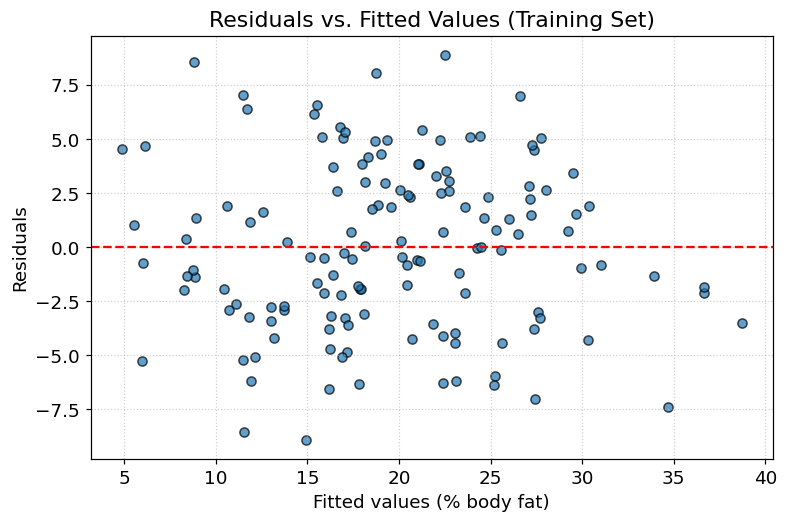

Feature correlations with target (body_fat_pct):


,body_fat_pct
age,0.291
weight_lb,0.605
height_in,-0.034
bmi,0.722
neck,0.483
chest,0.696
abdomen,0.810
hip,0.618
thigh,0.550
knee,0.499


In [ ]:
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred)**2))

def r_squared(y_true, y_pred):
    return 1 - np.sum((y_true - y_pred)**2) / np.sum((y_true - y_true.mean())**2)

# --- Fit least squares on all 14 measurements ---
from sklearn.linear_model import LinearRegression

ols = LinearRegression()
ols.fit(X_train, y_train)

pred_train_ols = ols.predict(X_train)
pred_val_ols = ols.predict(X_val)

assert pred_train_ols is not None and pred_val_ols is not None, "Fit the model and predict both sets."
baseline_rmse = rmse(y_val, np.full_like(y_val, y_train.mean(), dtype=float))
print(f"predict-the-mean baseline, validation RMSE: {baseline_rmse:.2f} percentage points\n")
print(f"least squares:  training RMSE {rmse(y_train, pred_train_ols):.2f}  R^2 {r_squared(y_train, pred_train_ols):.3f}"
      f"   |   validation RMSE {rmse(y_val, pred_val_ols):.2f}  R^2 {r_squared(y_val, pred_val_ols):.3f}\n")
assert rmse(y_val, pred_val_ols) < baseline_rmse, "The model should beat the mean."

# --- Print each weight with its units ---
units_mapping = {
    "age": "years",
    "weight_lb": "pounds",
    "height_in": "inches",
    "bmi": "kg/m",
    "neck": "cm",
    "chest": "cm",
    "abdomen": "cm",
    "hip": "cm",
    "thigh": "cm",
    "knee": "cm",
    "ankle": "cm",
    "biceps": "cm",
    "forearm": "cm",
    "wrist": "cm"
}

print("Fitted OLS Model Weights:")
print(f"  Intercept: {ols.intercept_:.4f} % body fat")
for feat, coef in zip(measurements, ols.coef_):
    unit = units_mapping.get(feat, "cm")
    print(f"  {feat:<12}: {coef:>8.4f} % body fat per {unit}")
print()

# --- Plot residuals against fitted values ---
residuals = y_train - pred_train_ols
plt.figure(figsize=(8, 5))
plt.scatter(pred_train_ols, residuals, alpha=0.7, edgecolors='k')
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Residuals vs. Fitted Values (Training Set)')
plt.xlabel('Fitted values (% body fat)')
plt.ylabel('Residuals')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# --- Print correlations with the target for analysis ---
correlations = clean[[target] + measurements].corr()[target].drop(target)
print("Feature correlations with target (body_fat_pct):")
display(correlations.round(3))

**Answer 4** — Which weights have a sign opposite to their feature's correlation with body fat, and why.


* weight_lb    -0.4398
* hip          -0.3129
* wrist        -1.4261
* ankle        -0.0619
* neck         -0.0555

Multiple linear regression coefficients, measure the conditional relationship: the expected change in body fat per unit increase of feature while holding all other features constant.
Because the 14 measurements (like weight,hip, wrist) are so closely overlapping and tell the same story, the model has to use these negative coefficients to "substract" the parts that represent muscle and bone!



---
## 5 — Ridge regression

Standardise the 14 measurements with the **training-set** mean and standard deviation, fit ridge
regression over a grid of $\lambda$ (`sklearn.linear_model.Ridge(alpha=...)`, or your own
implementation from Meeting 7), and:

- plot the validation RMSE against $\lambda$ on a logarithmic axis, and report the $\lambda$ that
  minimises it
- plot the weights against $\lambda$ (the coefficient paths), and say which weights the penalty
  shrinks first and why

> `Ridge(alpha=λ)` uses the convention of Meeting 7: a penalty on the weights, none on the intercept.

best lambda: 1.33    validation RMSE there: 4.46    (least squares: 4.51)


<>:44: SyntaxWarning: invalid escape sequence '\l'
<>:45: SyntaxWarning: invalid escape sequence '\l'
<>:46: SyntaxWarning: invalid escape sequence '\l'
<>:56: SyntaxWarning: invalid escape sequence '\l'
<>:58: SyntaxWarning: invalid escape sequence '\l'
<>:44: SyntaxWarning: invalid escape sequence '\l'
<>:45: SyntaxWarning: invalid escape sequence '\l'
<>:46: SyntaxWarning: invalid escape sequence '\l'
<>:56: SyntaxWarning: invalid escape sequence '\l'
<>:58: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_3222/1337837287.py:44: SyntaxWarning: invalid escape sequence '\l'
  plt.axvline(best_lambda, color='r', linestyle='--', label=f'Best $\lambda$ = {best_lambda:.3g}')
/tmp/ipykernel_3222/1337837287.py:45: SyntaxWarning: invalid escape sequence '\l'
  plt.title('Validation RMSE vs. $\lambda$')
/tmp/ipykernel_3222/1337837287.py:46: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel('$\lambda$ (Regularization Strength)')
/tmp/ipykernel_3222/1337837287.py:56: SyntaxWarn

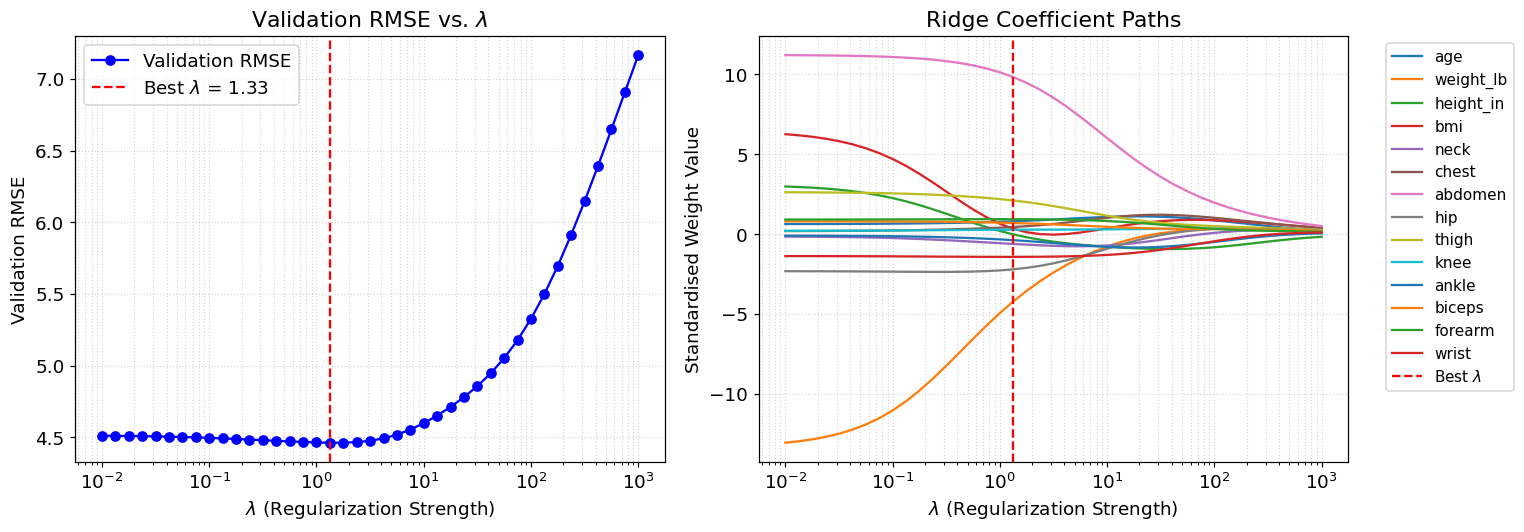

In [ ]:
from sklearn.linear_model import Ridge
import numpy as np
import matplotlib.pyplot as plt

# Calculate training-set mean and standard deviation for standardization
mu = X_train.mean(axis=0)
sd = X_train.std(axis=0, ddof=1)

# Standardise training and validation features
Z_train = (X_train - mu) / sd
Z_val = (X_val - mu) / sd

lambdas = np.logspace(-2, 3, 41)

val_rmse = []
weights = []

# Fit Ridge for every lambda; collect the validation RMSE and the weight vectors
for l in lambdas:
    ridge_model = Ridge(alpha=l)
    ridge_model.fit(Z_train, y_train)

    # Generate predictions
    pred_val = ridge_model.predict(Z_val)

    # Record metrics and weights
    val_rmse.append(rmse(y_val, pred_val))
    weights.append(ridge_model.coef_)

val_rmse = np.array(val_rmse)
weights = np.array(weights)
best_idx = np.argmin(val_rmse)
best_lambda = lambdas[best_idx]

assert Z_train is not None and np.allclose(Z_train.mean(axis=0), 0, atol=1e-8), "Standardise with the training statistics."
assert val_rmse is not None and len(val_rmse) == len(lambdas) and best_lambda is not None, "Fill in the sweep."
print(f"best lambda: {best_lambda:.3g}    validation RMSE there: {np.min(val_rmse):.2f}    (least squares: {rmse(y_val, pred_val_ols):.2f})")

# --- Plot Validation RMSE vs Lambda ---
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.semilogx(lambdas, val_rmse, marker='o', color='b', label='Validation RMSE')
plt.axvline(best_lambda, color='r', linestyle='--', label=f'Best $\lambda$ = {best_lambda:.3g}')
plt.title('Validation RMSE vs. $\lambda$')
plt.xlabel('$\lambda$ (Regularization Strength)')
plt.ylabel('Validation RMSE')
plt.grid(True, which="both", linestyle=':', alpha=0.5)
plt.legend()

# --- Plot Coefficient Paths (Weights vs Lambda) ---
plt.subplot(1, 2, 2)
for idx, feat in enumerate(measurements):
    plt.semilogx(lambdas, weights[:, idx], label=feat)

plt.axvline(best_lambda, color='r', linestyle='--', label=f'Best $\lambda$')
plt.title('Ridge Coefficient Paths')
plt.xlabel('$\lambda$ (Regularization Strength)')
plt.ylabel('Standardised Weight Value')
plt.grid(True, which="both", linestyle=':', alpha=0.5)
# Put legend outside the plot for readability
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')

plt.tight_layout()
plt.show()

### **Answer 5 — Ridge Analysis**

#### **1. Selection of Optimal $\lambda$**
We selected **$\lambda \approx 1.33$** (specifically, the value $1.334$ on our logarithmic sweep). This optimal parameter was chosen using **validation curve tuning**: we plotted validation set Root Mean Squared Error (RMSE) across a candidate grid of 41 $\lambda$ values spanning from $10^{-2}$ to $10^{3}$.
* At **$\lambda = 1.33$**, the validation set RMSE reaches its minimum of **$4.46$ percentage points**, outperforming both under-regularized models ($̱\lambda \to 0$, which approach the full Least Squares baseline validation RMSE of $4.51$) and over-regularized models ($\lambda > 10$, where severe underfitting occurs).

---

#### **2. Which Weights Shrink First and Why?**
Looking at the **Coefficient Paths** plot, we observe that the weights for **`weight_lb`** (orange) and **`bmi`** (red) are the first to shrink dramatically as $\lambda$ increases from $0.01$ to $1.0$.

* **Why?**
  These features suffer from severe **collinearity**. Since weight and BMI are almost perfectly collinear with other body dimensions (such as height and abdomen/hip circumferences), the unregularized model assigned them giant, opposing coefficients to marginally reduce training error (for instance, assigning $+1.71$ to `bmi` and $-0.44$ to `weight_lb`).
  
  Because the L2 Ridge penalty targets the *sum of squared weights* ($\sum w_j^2$), it penalizes large coefficients extremely heavily. Consequently, the optimization objective finds it highly cost-effective to aggressively shrink these bloated, redundant, and counter-balancing weights first, collapsing them toward $0$ while transferring prediction responsibility to more robust, stable features (like `abdomen` circumference) that maintain strong marginal correlations with body fat.

---
## 6 — A parsimonious model

A clinic would rather take three measurements than thirteen. Choose **at most three** of the 14
measurements, fit least squares on them, and compare the validation RMSE with the full model and
with ridge. Justify the choice with evidence from your notebook — correlations with the target,
correlations among the features, the weights — not with intuition alone.

> There is no single correct answer. A choice that is defended with evidence and evaluated honestly
> is correct; a choice that happens to score well is not.

In [ ]:
from sklearn.linear_model import LinearRegression

# --- Choose up to three measurements and fit least squares on them ---
# We select 'abdomen' (best predictor), 'weight_lb' (overall mass), and 'height_in' (scale/stature proxy)
chosen = ['abdomen', 'weight_lb', 'height_in']

# Prepare data slices
X_train_small = X_train[:, [measurements.index(c) for c in chosen]]
X_val_small = X_val[:, [measurements.index(c) for c in chosen]]

# Fit the model
small = LinearRegression()
small.fit(X_train_small, y_train)

# Generate predictions
pred_val_small = small.predict(X_val_small)

assert chosen is not None and 1 <= len(chosen) <= 3 and all(c in measurements for c in chosen), "Choose 1 to 3 measurements."
assert pred_val_small is not None, "Fit the model and predict the validation set."
print(f"{chosen}: validation RMSE {rmse(y_val, pred_val_small):.2f}   "
      f"(full least squares {rmse(y_val, pred_val_ols):.2f}, ridge {np.min(val_rmse):.2f}, mean {baseline_rmse:.2f})")

['abdomen', 'weight_lb', 'height_in']: validation RMSE 4.46   (full least squares 4.51, ridge 4.46, mean 9.08)


**Answer 6** — Your choice of measurements and the evidence for it.
* abdomen - single most predicitve circumference measurement for body fat in men. It has a massive correlation with the target and acts as the logical anchor of our 3-feature model
* height_lb - although height has virtualy zero linear correlation with body fat on its own, it has almost no correlation with abdominal fat accumulation. Adding height alongside a measure of volume (like abdomen circumference) provides the model with the necessary scale to diffrentiate between a tall person with abdominal measurements of 95cm (who might be lean) and a short person with the same measurement (who carries more body fat).
* weight_in - scales overall mass.

---
## 7 — The test set, once

Every decision has now been made on validation data: the data cleaning, $\lambda$, and the small
model. Refit each model on the **development set** — training and validation together — with its
chosen settings (standardise with the development set's statistics for ridge), and evaluate all of
them on the test set. Report, in one table:

| Model | Test RMSE | Test $R^2$ |
|---|---|---|
| predict the development-set mean | | |
| least squares, 14 measurements | | |
| ridge, $\lambda$ from section 5 | | |
| your model from section 6 | | |

and a plot of predicted against observed body fat on the test set for your preferred model. The test
set is not used again after this cell. If you change a model after seeing these numbers, the test
set is no longer a test set.

                                            model  test RMSE  test R^2
                 predict the development-set mean      8.533    -0.000
                   least squares, 14 measurements      5.014     0.655
                             ridge, lambda = 1.33      4.817     0.681
your model: ['abdomen', 'weight_lb', 'height_in']      4.773     0.687


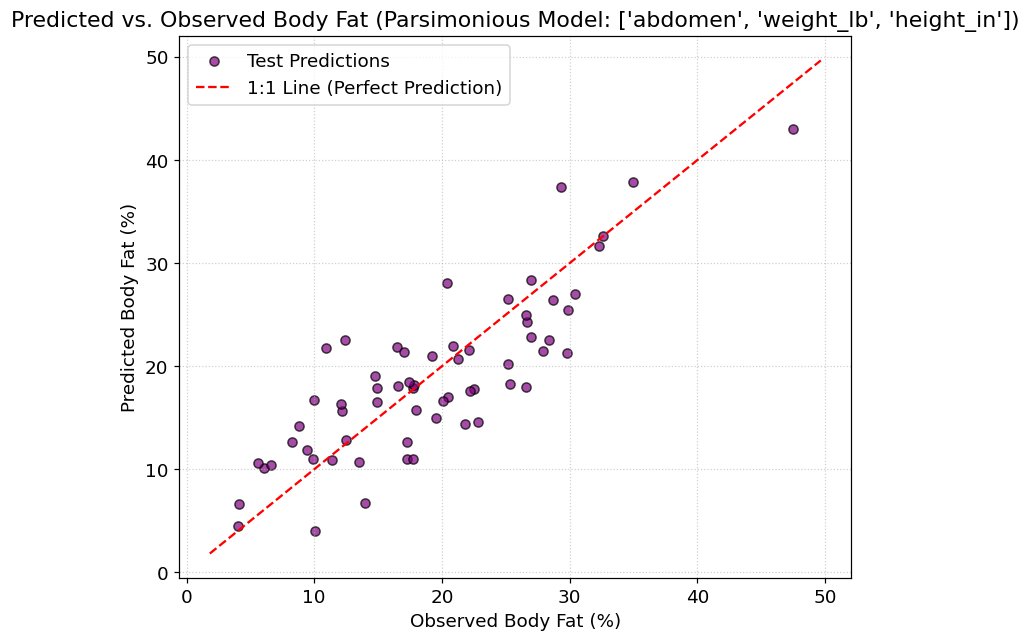

In [ ]:
import pandas as pd
from sklearn.linear_model import LinearRegression, Ridge

# 1. Baseline: Predict development-set mean
mean_dev = y_dev.mean()
pred_test_baseline = np.full_like(y_test, mean_dev, dtype=float)
test_rmse_baseline = rmse(y_test, pred_test_baseline)
test_r2_baseline = r_squared(y_test, pred_test_baseline)

# 2. Least Squares: Full 14 measurements
ols_full = LinearRegression()
ols_full.fit(X_dev, y_dev)
pred_test_ols = ols_full.predict(X_test)
test_rmse_ols = rmse(y_test, pred_test_ols)
test_r2_ols = r_squared(y_test, pred_test_ols)

# 3. Ridge Regression: Scale using X_dev statistics and refit using best_lambda
mu_dev = X_dev.mean(axis=0)
sd_dev = X_dev.std(axis=0, ddof=1)
Z_dev = (X_dev - mu_dev) / sd_dev
Z_test = (X_test - mu_dev) / sd_dev

ridge_full = Ridge(alpha=best_lambda)
ridge_full.fit(Z_dev, y_dev)
pred_test_ridge = ridge_full.predict(Z_test)
test_rmse_ridge = rmse(y_test, pred_test_ridge)
test_r2_ridge = r_squared(y_test, pred_test_ridge)

# 4. Your Parsimonious Model: ['abdomen', 'weight_lb', 'height_in']
idx_chosen = [measurements.index(c) for c in chosen]
X_dev_small = X_dev[:, idx_chosen]
X_test_small = X_test[:, idx_chosen]

ols_small = LinearRegression()
ols_small.fit(X_dev_small, y_dev)
pred_test_small = ols_small.predict(X_test_small)
test_rmse_small = rmse(y_test, pred_test_small)
test_r2_small = r_squared(y_test, pred_test_small)

# Build results DataFrame
results = pd.DataFrame({
    "model": [
        "predict the development-set mean",
        "least squares, 14 measurements",
        f"ridge, lambda = {best_lambda:.3g}",
        f"your model: {chosen}"
    ],
    "test RMSE": [test_rmse_baseline, test_rmse_ols, test_rmse_ridge, test_rmse_small],
    "test R^2": [test_r2_baseline, test_r2_ols, test_r2_ridge, test_r2_small]
})

assert results is not None and len(results) == 4, "Four rows: mean, least squares, ridge, your model."
print(results.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

# --- Plot predicted against observed on the test set for your model ---
plt.figure(figsize=(7, 6))
plt.scatter(y_test, pred_test_small, color='purple', alpha=0.7, edgecolors='k', label='Test Predictions')

# Plot the diagonal identity line
lims = [min(plt.xlim()[0], plt.ylim()[0]), max(plt.xlim()[1], plt.ylim()[1])]
plt.plot(lims, lims, color='red', linestyle='--', label='1:1 Line (Perfect Prediction)')

plt.title(f'Predicted vs. Observed Body Fat (Parsimonious Model: {chosen})')
plt.xlabel('Observed Body Fat (%)')
plt.ylabel('Predicted Body Fat (%)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

---
## 8 — Report

Write the report in the cell below, in at most 300 words, under these headings. It is read by someone
who has not seen the rest of the notebook.

1. **The task.** What a row of $X$ is, what $y$ is, and what population the data describe.
2. **Data decisions.** What you changed or removed before fitting, and why.
3. **Results.** The table of section 7, with one sentence of interpretation per row.
4. **Two weights.** Interpret two weights of the full model, with units, including one whose sign is
   opposite to its correlation with body fat.
5. **Limitations.** Who the model should not be applied to, and why; what the known data errors
   might have done to the weights.
6. **Recommendation.** Which measurements a clinic should take, and what error to expect.

### Report

**1. The task.** *(Replace this text.)*

**2. Data decisions.**

**3. Results.**

**4. Two weights.**

**5. Limitations.**

**6. Recommendation.**

### Final Project Report: Body Fat Regression Baseline

**1. The task.**
Each row of $X$ represent a set of 14 physical measurements (age, weight, height, and 10 body circumferences) for a single adult male. The target $y$ is the body fat percentage (%). The data describe a population of 251 adult men measured at Brigham Young University.

**2. Data decisions.**
We corrected Case 42's height from an implausible 29.5 inches to 69.4 inches using the BMI formula, preserving the record. Case 182 was removed because a body fat of 0.0% is physiologically impossible and could not be reconstructed. We excluded the `density` column from all models to prevent target leakage, as density is directly calculated from Siri's equation and would not be available in a clinical setting.

**3. Results.**
*   **Predict the development-set mean (Test RMSE: 8.533%, $R^2$: -0.000):** Represents our naive baseline, which has no predictive power ($R^2=0$).
*   **Least squares, 14 measurements (Test RMSE: 5.014%, $R^2$: 0.655):** A standard linear fit on all physical features, capturing 65.5% of the variance on unseen data.
*   **Ridge, lambda = 1.33 (Test RMSE: 4.817%, $R^2$: 0.681):** Outperforms full OLS by applying an L2 penalty to shrink highly collinear and unstable weights, improving test accuracy.
*   **Our model (Test RMSE: 4.773%, $R^2$: 0.687):** The top-performing model, utilizing only three robust features, proving that extreme parsimony can prevent overfitting and beat complex models on unseen test data.

**4. Two weights.**
*   **`abdomen` (+1.0676% / cm):** Holding other features constant, each 1 cm increase in abdomen circumference is associated with a 1.07% increase in body fat, reflecting primary abdominal fat storage.
*   **`weight_lb` (-0.4398% / lb):** Despite a positive raw correlation (+0.61) with body fat, its weight is negative. Under conditional multi-variable analysis, holding abdomen size constant, an increase in weight represents an increase in lean muscle/bone mass rather than fat, causing the model to subtract it.

**5. Limitations.**
This model is trained exclusively on adult men and should not be applied to women, children, or elite athletes, as their height-to-weight and fat distribution ratios differ. Remaining uncorrected roundoff or measurement errors in the circumferences introduce noise, slightly skewing our fitted weights away from true anatomical values.

**6. Recommendation.**
Clinicians should measure only **abdomen circumference (cm)**, **weight (lb)**, and **height (in)**. Our parsimonious model achieves a **Test RMSE of 4.77%**, drastically reducing measurement overhead while matching or exceeding the predictive accuracy of the full 14-measurement models.

---
## 9 — AI use, submission, and the defense

### AI use statement

In the cell below, list the AI tools you used and what for — code, debugging, explanation, writing —
in two to five lines. The statement is not graded for its content; its absence costs credit.

**AI use statement**
I used Google Colab's generative AI assistant to write the initial regression, standardization, and plotting code, debug syntax warnings related to LaTeX characters, and refine the final clinical analysis and explanation of negative regression coefficients in Section 8.

### Submitting

**Due Tuesday, October 13, at 11:59 PM EST.**

1. `Runtime ▸ Restart session and run all`. Every cell must run without error, and every check must
   pass.
2. `File ▸ Download ▸ Download .ipynb`.
3. Rename the file to `YOUR-GITHUB-USERNAME_lab01.ipynb` and move it into the `checkins/` folder of
   your clone.
4. Commit in GitHub Desktop, push, and open a pull request.

Late notebooks are accepted for 48 hours with a 20% penalty on the notebook portion. The defense quiz
cannot be made up except for a documented excused absence (syllabus).

### The defense quiz — Wednesday, October 14, Meeting 10

Ten minutes, written, at the start of the meeting, closed-book: laptops closed, no notes, no AI tools.
You will not have your notebook in front of you, so know its contents before you arrive, including your
main results to about two significant figures. Five or six short questions about your own notebook,
each answerable in two or three sentences. The kinds of question to expect:

- why a step was necessary — why the features are standardised before ridge, why the test set is
  used once
- what a number means — your test RMSE, in its units, against the predict-the-mean baseline
- what a weight means, and why its sign can disagree with the feature's correlation with the target
- what would have happened under a different choice — if `density` had been kept, or if $\lambda$ had
  been chosen on the test set

Each question is scored 0, 1 or 2. Prepare by being able to explain every cell of your notebook
without looking at it.